# EEG Denoising

1. Notch filter with (50Hz)60Hz and bandpass filter with 0.5(-1)-30Hz(-50Hz) → this removes powerline noise and generally removes all frequencies that are unwanted in our data
2. Remove extremely high amplitudes with Amplitude based epoch rejection
3. Remove Artificats with ICA
4. Normalize data by applying a z-transform
5. Visual inspection


## 0. Load the data

In [46]:
import pandas as pd
import numpy as np
import pickle
import mne
import scipy.signal
import matplotlib.pyplot as plt

In [2]:
PATH_TO_DATA = "../../data/eeg_data_v2"

In [24]:
df = pd.read_pickle(f"{PATH_TO_DATA}/pickle/000.pkl")
df

,genre,EEG_Ch1,EEG_Ch2,EEG_Ch3,EEG_Ch4,EEG_Ch5,EEG_Ch6,EEG_Ch7,EEG_Ch8
Song0,disco,"[-26530.947, -26530.41, -26533.898, -26533.227...","[260725.12, 260731.03, 260778.9, 260804.66, 26...","[-69.1956, -69.4638, -69.53085, -69.12855, -69...","[52945.63, 52944.625, 52940.066, 52937.113, 52...","[-44293.766, -44293.902, -44297.723, -44302.48...","[154275.88, 154294.19, 154328.05, 154339.58, 1...","[57312.797, 57311.523, 57306.9, 57302.67, 5730...","[231145.36, 231153.6, 231199.6, 231215.16, 231..."
Song1,rock,"[-27546.555, -27540.787, -27549.57, -27544.408...","[259998.64, 259957.61, 259889.89, 259923.42, 2...","[-68.7933, -69.26265, -69.26265, -69.12855, -6...","[54323.777, 54323.977, 54324.914, 54324.914, 5...","[-43968.105, -43966.094, -43969.11, -43963.746...","[153511.44, 153486.84, 153455.39, 153498.44, 1...","[56500.688, 56501.895, 56494.586, 56504.44, 56...","[218154.08, 218126.25, 218075.44, 218105.2, 21..."
Song2,hiphop,"[-29543.705, -29547.527, -29546.254, -29546.79...","[257900.25, 257871.48, 257840.7, 257854.05, 25...","[-69.4638, -69.12855, -69.0615, -69.3297, -68....","[55740.41, 55739.938, 55758.242, 55753.016, 55...","[-44948.105, -44946.566, -44940.53, -44939.594...","[151438.6, 151405.53, 151397.16, 151410.7, 151...","[54342.215, 54337.992, 54343.69, 54345.367, 54...","[211008.56, 210966.98, 210942.58, 210960.62, 2..."
Song3,reggae,"[-31023.096, -31018.068, -31020.213, -31018.33...","[256096.0, 256115.31, 256163.45, 256191.69, 25...","[-69.3297, -69.3297, -69.3297, -69.53085, -69....","[56282.64, 56288.074, 56288.273, 56286.598, 56...","[-45704.027, -45698.867, -45698.598, -45697.05...","[149702.06, 149730.23, 149764.48, 149767.9, 14...","[52735.363, 52737.707, 52741.465, 52742.402, 5...","[202956.12, 202982.55, 203024.78, 203041.88, 2..."
Song4,pop,"[-31123.402, -31127.092, -31129.102, -31125.68...","[255426.38, 255362.08, 255365.1, 255409.0, 255...","[-68.99445, -69.1956, -69.26265, -68.99445, -6...","[57460.777, 57462.92, 57459.57, 57461.38, 5745...","[-45349.336, -45351.816, -45357.582, -45352.41...","[149071.86, 149033.31, 149035.72, 149068.52, 1...","[52107.906, 52102.477, 52096.508, 52101.27, 52...","[193770.67, 193716.64, 193711.81, 193746.88, 1..."
Song5,reggae,"[-31757.896, -31752.064, -31748.78, -31743.75,...","[254645.38, 254681.98, 254666.1, 254606.48, 25...","[-68.99445, -69.12855, -68.99445, -69.0615, -6...","[57947.227, 57952.59, 57957.215, 57957.418, 57...","[-45000.54, -44995.98, -44995.51, -44992.695, ...","[148097.42, 148117.27, 148103.6, 148080.27, 14...","[51336.562, 51339.85, 51342.13, 51343.27, 5134...","[185688.61, 185729.97, 185715.3, 185673.11, 18..."
Song6,jazz,"[-32086.375, -32087.783, -32090.332, -32093.68...","[253990.83, 253969.11, 254009.94, 254039.05, 2...","[-69.1956, -69.3297, -68.72625, -69.12855, -69...","[58237.484, 58237.35, 58233.46, 58232.926, 582...","[-44866.91, -44863.56, -44868.92, -44867.445, ...","[147340.56, 147338.55, 147378.58, 147391.25, 1...","[50514.4, 50513.055, 50508.9, 50503.734, 50501...","[179221.03, 179205.34, 179242.16, 179262.6, 17..."
Song7,disco,"[-32289.201, -32289.402, -32292.354, -32295.90...","[253260.05, 253315.64, 253320.47, 253282.84, 2...","[-69.12855, -68.99445, -68.9274, -69.1956, -69...","[58326.324, 58330.816, 58330.816, 58325.656, 5...","[-44787.457, -44786.113, -44791.88, -44800.934...","[146494.06, 146535.83, 146529.27, 146486.69, 1...","[49965.527, 49965.39, 49963.047, 49957.75, 499...","[174134.89, 174185.78, 174186.52, 174152.19, 1..."
Song8,country,"[-32699.748, -32696.328, -32689.088, -32691.43...","[252825.17, 252851.39, 252838.52, 252801.9, 25...","[-68.86035, -68.7933, -68.99445, -69.12855, -6...","[58388.95, 58392.035, 58395.656, 58393.71, 583...","[-44429.945, -44427.062, -44423.91, -44424.582...","[145903.55, 145914.14, 145904.08, 145884.11, 1...","[49351.15, 49351.348, 49356.176, 49357.316, 49...","[161240.36, 161249.34, 161227.42, 161196.31, 1..."
Song9,jazz,"[-32517.506, -32513.818, -32512.143, -32506.91...","[253166.98, 

In [ ]:
with open(f"{PATH_TO_DATA}/pickle/000.pkl", "rb") as f:
  data = pickle.load(f)

In [5]:
df.index.name = 'Song'

In [ ]:
# Check whether the shape seems right
len(df.loc["Song0", "EEG_Ch1"])

7733

In [15]:
# For frequency filtering, all signal data has to be concatanated since we have to look at the whole session
# we therefore need to concatenate all arrays of each channel and store in a list, where each segment starts/ends

def get_concatentated_channel_data(channel_name):
  column = df[channel_name] # get the channel
  ret = []
  offsets = []
  for i in range(len(column)):
    arr = column.iloc[i]
    ret.extend(arr)
    offsets.append(len(arr))
  return ret, offsets



In [ ]:
offset_accumulated_list = []
channel_data_list = []
for i in range(1, 9, 1):
  concatenated_channel_data, offsets = get_concatentated_channel_data(f"EEG_Ch{i}")
  channel_data_list.append(concatenated_channel_data)
  offset_accumulated_list.append(offsets)

(8, 50)


In [26]:
print(np.shape(channel_data_list))

(8, 376819)


In [34]:
channel_data_list_np = np.array(channel_data_list)

In [ ]:
# Source: https://swharden.com/blog/2020-09-23-signal-filtering-in-python/

def bandpass(data, edges, sample_rate, poles=5):
  sos = scipy.signal.butter(poles, edges, 'bandpass', fs=sample_rate, output='sos')
  filtered_data = scipy.signal.sosfiltfilt(sos, data)
  return filtered_data

In [55]:
def notch_filter(data, f0, sample_rate, Q=30):
  b, a = scipy.signal.iirnotch(f0, Q, fs=sample_rate)
  return scipy.signal.filtfilt(b, a, data)

In [44]:
sample_rate = 250
filtered = np.zeros_like(channel_data_list_np)
for channel in range(channel_data_list_np.shape[0]):
  filtered[channel, :] = bandpass(channel_data_list_np[channel, :], [0.5, 30], sample_rate)

print(filtered.shape)

(8, 376819)


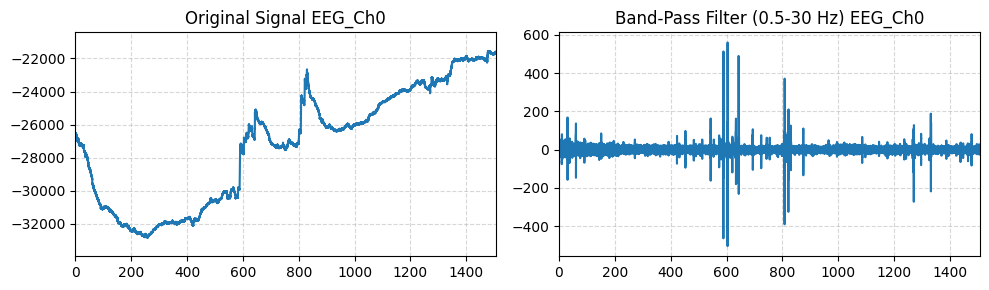

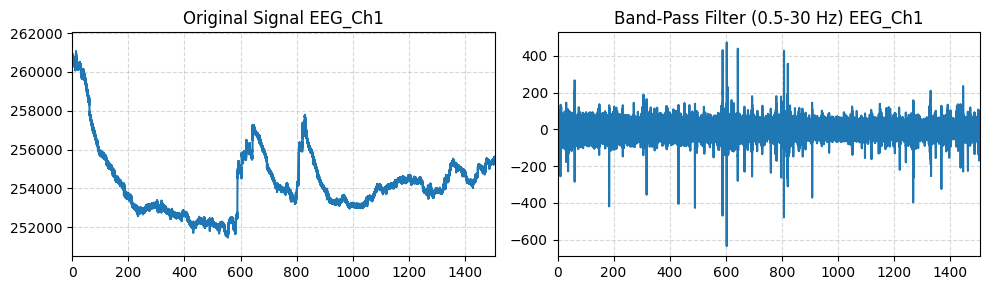

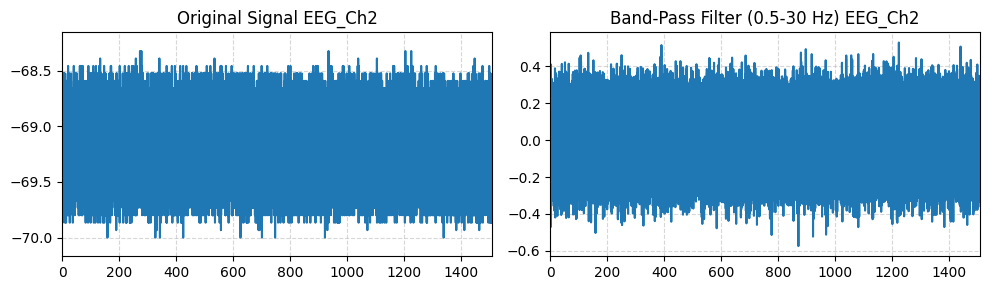

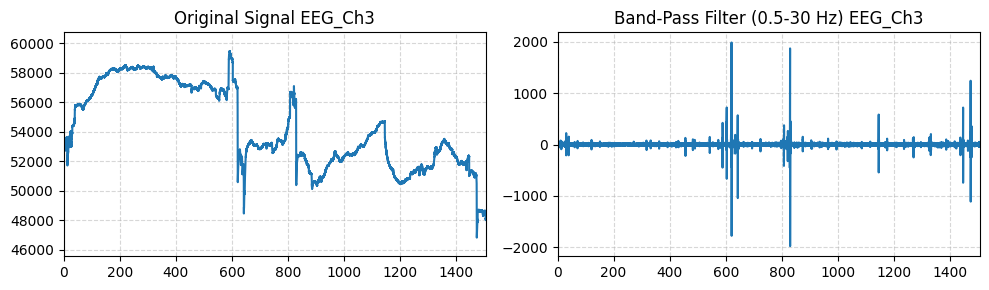

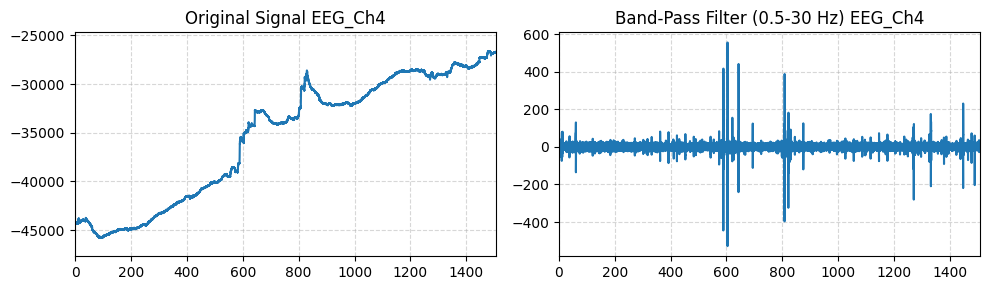

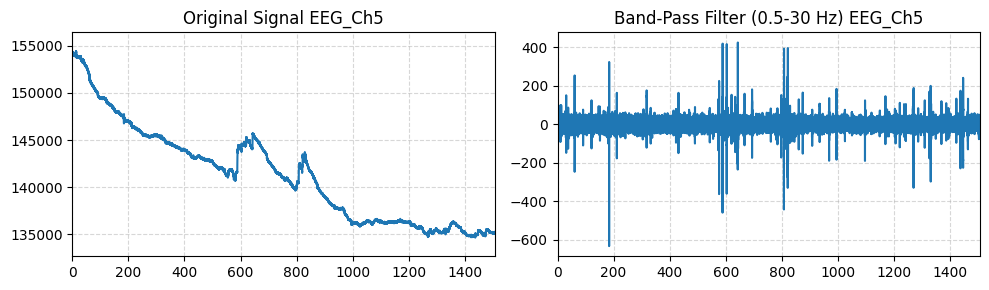

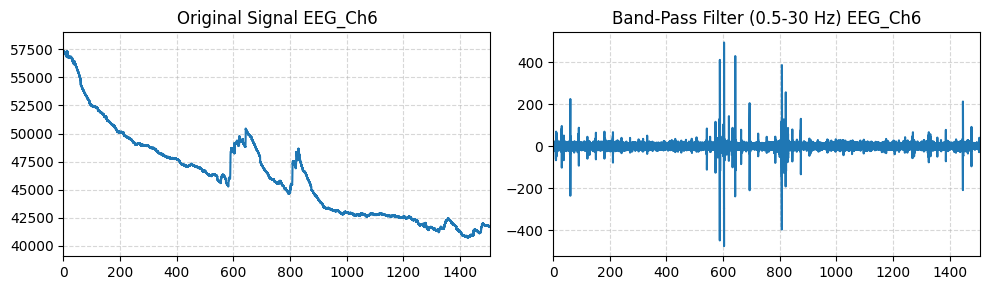

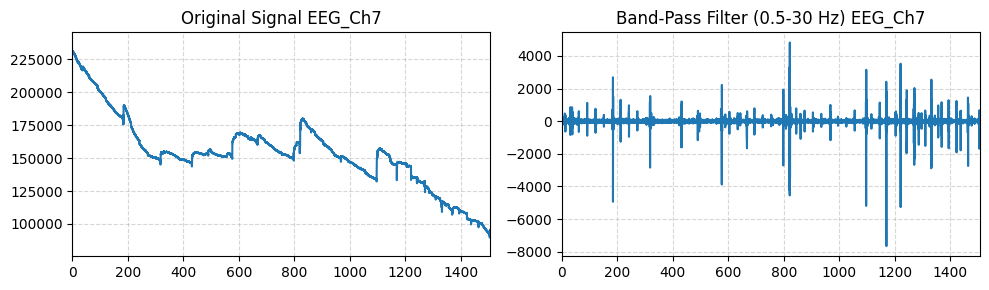

In [ ]:
# visualize channels
for i in range (channel_data_list_np.shape[0]):
  times = np.arange(len(channel_data_list_np[i]))/sample_rate
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3), sharex=True, sharey=False)
  ax1.plot(times, channel_data_list_np[i])
  ax1.set_title(f"Original Signal EEG_Ch{i+1}")
  ax1.margins(0, .1)
  ax1.grid(alpha=.5, ls='--')
  ax2.plot(times, filtered[i])
  ax2.set_title(f"Band-Pass Filter (0.5-30 Hz) EEG_Ch{i+1}")
  ax2.grid(alpha=.5, ls='--')
  plt.tight_layout()
  plt.show()

In [56]:
filtered_notch = np.zeros_like(filtered)
for channel in range(filtered.shape[0]):
  filtered_notch[channel, :] = notch_filter(filtered[channel, :], 50, sample_rate)

print(filtered_notch.shape)

(8, 376819)


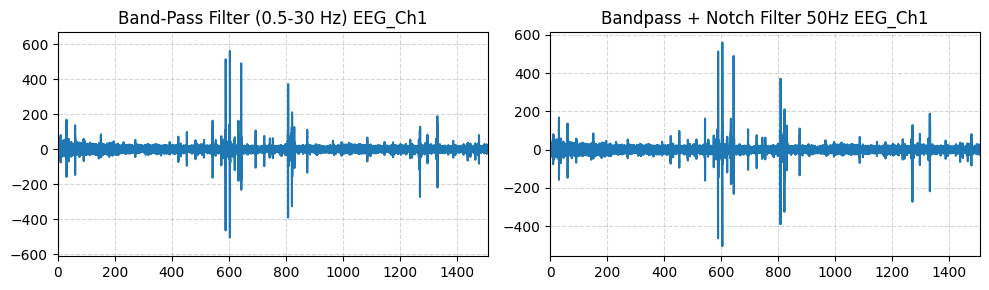

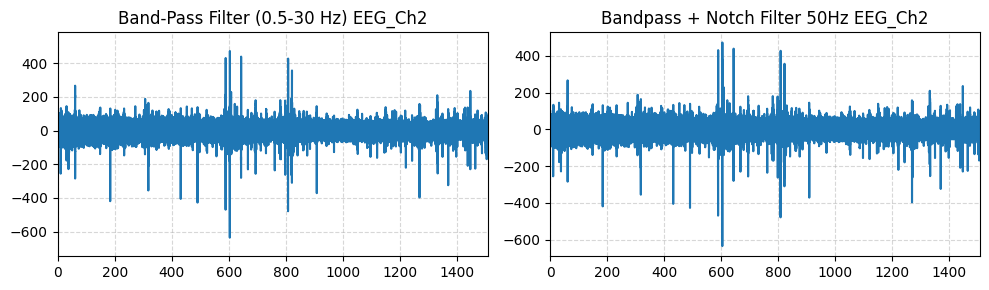

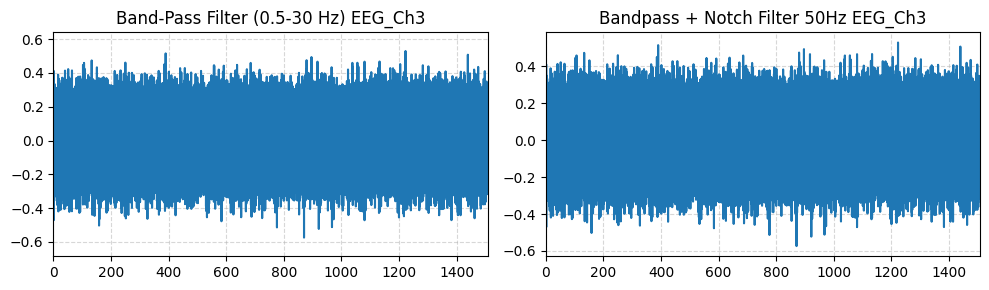

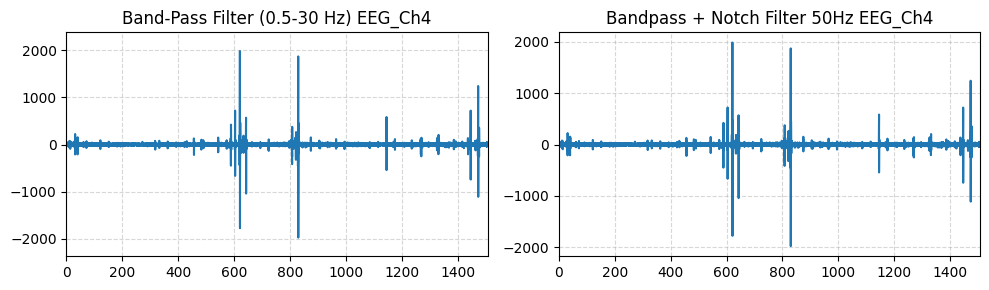

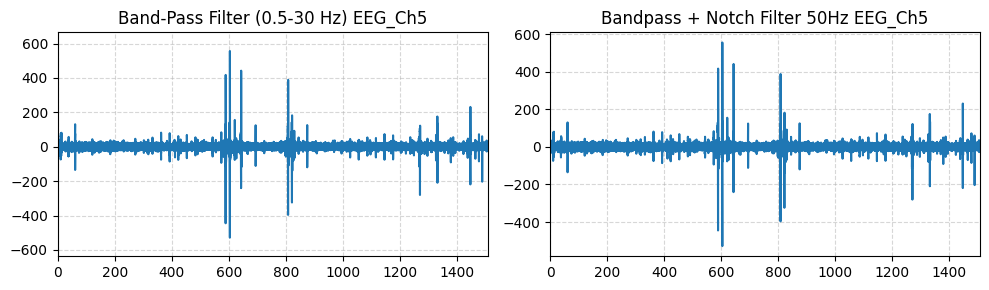

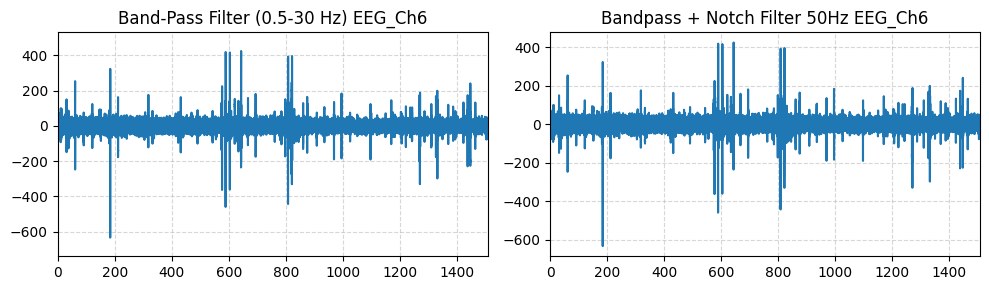

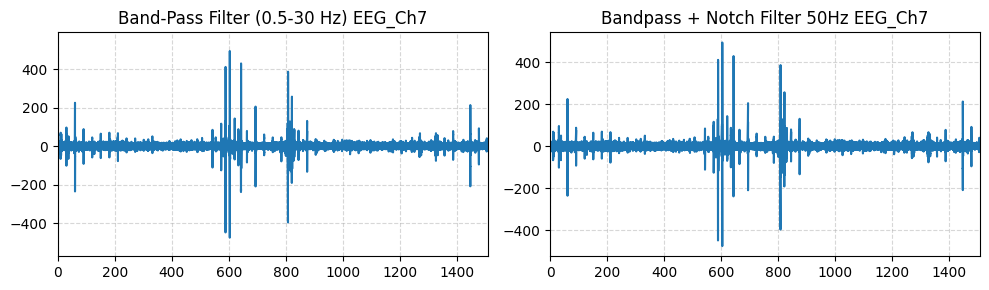

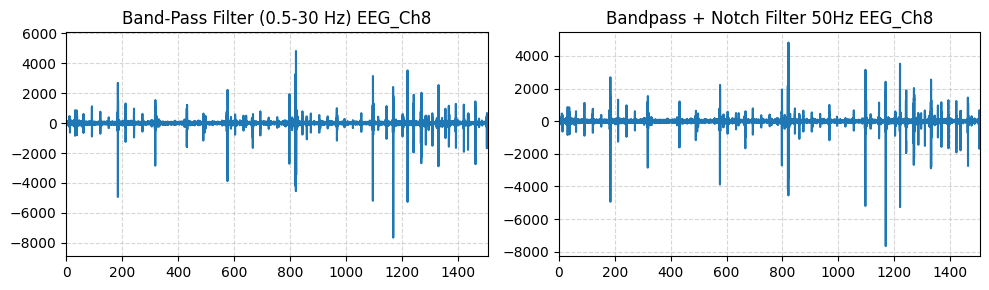

In [57]:
# visualize channels
for i in range (filtered.shape[0]):
  times = np.arange(len(filtered[i]))/sample_rate
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3), sharex=True, sharey=False)
  ax1.plot(times, filtered[i])
  ax1.set_title(f"Band-Pass Filter (0.5-30 Hz) EEG_Ch{i+1}")
  ax1.margins(0, .1)
  ax1.grid(alpha=.5, ls='--')
  ax2.plot(times, filtered_notch[i])
  ax2.set_title(f"Bandpass + Notch Filter 50Hz EEG_Ch{i+1}")
  ax2.grid(alpha=.5, ls='--')
  plt.tight_layout()
  plt.show()